# Modelagem e Avaliação dos Classificadores de Avaliações da Steam

Este notebook usa a base preparada no notebook `01_eda_preprocessamento.ipynb` (arquivo `Data/reviews_modelo.csv`) para treinar, avaliar e ajustar modelos de **classificação supervisionada**. O objetivo é identificar se uma avaliação é uma **recomendação positiva (1)** ou **negativa (0)**.

O notebook está organizado em quatro partes:
1. **Modelagem inicial** com três classificadores (Seções 3 a 14);
2. **Modelo de referência** para saber se os resultados são realmente bons (Seção 15);
3. **Ajuste dos modelos** para melhorar a identificação das avaliações negativas (Seções 16 a 19);
4. **Interpretação do modelo final**, base do produto apresentado na Etapa 3 (Seção 20).

## 1. Importação das bibliotecas

Todas as bibliotecas são importadas aqui, em uma única célula.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, GridSearchCV,
                                     StratifiedKFold, cross_val_predict)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

sns.set_theme(style="whitegrid")

## 2. Carregamento da base preparada

A base é lida do arquivo gerado pelo notebook 01. Ela já passou pela limpeza e normalização dos textos e não contém avaliações sem conteúdo (19.225 registros). A função `limpar_texto` é repetida aqui porque será usada na Seção 20, para limpar textos novos antes de classificá-los. É exatamente a mesma função do notebook 01.

In [2]:
PASTA_PROJETO = Path.cwd().parent
PASTA_FIGURAS = PASTA_PROJETO / "Docs" / "Figuras"
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)

df_modelo = pd.read_csv(PASTA_PROJETO / "Data" / "reviews_modelo.csv")

def limpar_texto(texto):
    texto = str(texto).lower()
    texto = re.sub(r"http\S+|www\S+", " ", texto)
    texto = re.sub(r"[^a-zA-ZÀ-ÿ\s']", " ", texto)
    texto = re.sub(r"\s+", " ", texto)
    return texto.strip()

print("Registros:", len(df_modelo))
print(df_modelo["alvo"].value_counts())

Registros: 19225
alvo
1    14391
0     4834
Name: count, dtype: int64


## 3. Método analítico: classificação supervisionada

**O que é.** Na classificação supervisionada, o modelo aprende com exemplos em que a resposta correta já é conhecida e depois prevê a classe de exemplos novos.

**Como se aplica neste projeto.**
- **Entrada (X):** o texto limpo da avaliação (`review_limpa`).
- **Saída (y):** a variável `alvo`, criada a partir de `voted_up` (1 = o jogador recomendou o jogo; 0 = não recomendou).
- O rótulo vem do próprio jogador, que marca se recomenda ou não o jogo. Por isso não foi necessário rotular nenhum texto manualmente.

**Por que este método.** O problema de negócio é identificar automaticamente a opinião expressa em milhares de textos livres. Como existe um rótulo conhecido para cada avaliação, a classificação supervisionada é a escolha natural e permite medir o acerto de forma objetiva (acurácia, precisão, recall e F1-Score).

**Limitação a considerar.** O rótulo `voted_up` representa a recomendação final do jogador, e um mesmo texto pode misturar elogios e críticas. Isso limita o desempenho máximo possível de qualquer modelo.

## 4. Separação dos dados em treino e teste

A base de 19.225 avaliações é dividida em dois conjuntos:

- **Treino (80%, 15.380 avaliações):** usado para o modelo aprender os padrões;
- **Teste (20%, 3.845 avaliações):** usado somente para medir o desempenho em textos que o modelo nunca viu.

Dois cuidados foram tomados:
- **Estratificação (`stratify=y`):** mantém a mesma proporção de avaliações positivas e negativas (aproximadamente 75% e 25%) nos dois conjuntos. Sem isso, o conjunto de teste poderia ter proporções diferentes por acaso.
- **`random_state=42`:** fixa o sorteio, para que qualquer pessoa que rode o notebook obtenha exatamente a mesma divisão.

O conjunto de teste **não é usado para escolher parâmetros nem modelos**. As escolhas das Seções 16 a 19 são feitas apenas com os dados de treino.

In [3]:
X = df_modelo["review_limpa"]
y = df_modelo["alvo"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Treinamento:", len(X_treino))
print("Teste:", len(X_teste))

Treinamento: 15380
Teste: 3845


## 5. Vetorização com TF-IDF

Os modelos de Machine Learning não leem texto: eles trabalham com números. O **TF-IDF** (Term Frequency × Inverse Document Frequency) transforma cada avaliação em um vetor de números.

**Como o peso de cada termo é calculado.**

- **TF (frequência do termo):** quantas vezes o termo $t$ aparece na avaliação $d$.
- **IDF (frequência inversa de documentos):** reduz o peso de termos presentes em muitas avaliações (como "the" ou "game") e valoriza termos mais específicos:

$$\text{idf}(t) = \ln\frac{1+N}{1+\text{df}(t)} + 1$$

em que $N$ é o número de avaliações e $\text{df}(t)$ é o número de avaliações que contêm o termo.

- **Peso final:** $\text{tfidf}(t,d) = \text{tf}(t,d) \times \text{idf}(t)$. Em seguida, cada vetor é normalizado para que avaliações longas e curtas fiquem em escala comparável.

**Configuração utilizada.**
- `ngram_range=(1, 2)`: considera palavras isoladas e pares de palavras seguidas. Os pares preservam informações que a palavra isolada perde, como em "not good" (negação) ou "worth it".
- `max_features=5000`: mantém os 5.000 termos mais frequentes, o que limita o tamanho dos vetores e reduz ruído de termos raros.
- As **stopwords foram mantidas**, pois palavras como "not" e "no" carregam o sentido da opinião.

**Resultado.** Cada avaliação passa a ser um vetor de 5.000 números. Termos como "recommend" ou "fun" tendem a receber peso em avaliações positivas, e termos como "refund" ou "crash" em avaliações negativas. É essa relação entre os termos e a variável-alvo `alvo` que os classificadores aprendem.

**Prevenção de vazamento de dados.** O vetorizador é ajustado (`fit`) **somente com os textos de treino**. Para o teste usa-se apenas `transform`, com o vocabulário e os pesos IDF aprendidos no treino. Assim, nenhuma informação do conjunto de teste influencia o treinamento.

In [4]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_treino_tfidf = tfidf.fit_transform(X_treino)
X_teste_tfidf = tfidf.transform(X_teste)

print("Formato dos dados de treinamento:", X_treino_tfidf.shape)
print("Formato dos dados de teste:", X_teste_tfidf.shape)

Formato dos dados de treinamento: (15380, 5000)
Formato dos dados de teste: (3845, 5000)


## 6. Modelos de classificação

Foram escolhidos três modelos de famílias diferentes, para comparar abordagens: um **probabilístico**, um **linear** e um **baseado em árvores**. Todos recebem a mesma entrada (a matriz TF-IDF) e preveem a mesma saída (`alvo`).

### Multinomial Naive Bayes (probabilístico)
Calcula, para cada avaliação, a probabilidade de pertencer a cada classe usando o teorema de Bayes:

$$P(c \mid d) \propto P(c) \cdot \prod_{t} P(t \mid c)^{x_t}$$

- $P(c)$ é a **probabilidade a priori** da classe, calculada no treino (cerca de 74,86% positiva e 25,14% negativa).
- $P(t \mid c)$ é a probabilidade de o termo $t$ aparecer em avaliações da classe $c$, estimada a partir dos pesos TF-IDF, com suavização de Laplace (`alpha=1`) para termos nunca vistos em uma classe.
- É "ingênuo" porque supõe que os termos são independentes entre si, o que é falso em textos, mas funciona bem na prática.
- **Ponto de atenção:** como a probabilidade a priori favorece a classe positiva, o modelo tende a classificar avaliações duvidosas como positivas.

### Regressão Logística (linear)
Atribui **um peso a cada um dos 5.000 termos** e calcula uma pontuação para a avaliação:

$$P(\text{positiva} \mid x) = \frac{1}{1 + e^{-(w \cdot x + b)}}$$

- Termos com peso positivo empurram a avaliação para "recomenda"; termos com peso negativo empurram para "não recomenda".
- Os pesos são aprendidos no treino, minimizando o erro de previsão, com regularização (`C=1` por padrão) para evitar ajuste excessivo.
- Por padrão, a avaliação é classificada como positiva quando $P \geq 0{,}5$.
- **Vantagem:** os pesos podem ser lidos, o que permite identificar os termos mais associados às avaliações negativas (Seção 20).

### Random Forest (árvores)
Combina muitas árvores de decisão (100 neste projeto).
- Cada árvore é treinada com uma amostra diferente dos dados e, a cada divisão, considera apenas um subconjunto dos termos.
- Cada divisão pergunta algo como "o termo X tem peso acima de um valor?", escolhendo a pergunta que melhor separa as classes (critério de Gini: $G = 1 - \sum_c p_c^2$).
- A classe final é decidida por **votação** das árvores.
- **Ponto de atenção:** em dados de texto, a representação TF-IDF é muito esparsa (a maioria dos termos tem peso zero em cada avaliação), o que costuma tornar as árvores menos eficientes que os modelos lineares.

### Resumo da comparação

| Modelo | Tipo | Como usa o texto | Risco neste projeto |
|---|---|---|---|
| Multinomial Naive Bayes | Probabilístico | Probabilidade de cada termo em cada classe | Favorece a classe majoritária |
| Regressão Logística | Linear | Um peso por termo | Também influenciada pelo desbalanceamento |
| Random Forest | Árvores | Perguntas sobre a presença de termos | Árvores têm dificuldade com dados esparsos |

## Treinamento dos modelos

Após a preparação dos textos e a aplicação da técnica TF-IDF, os dados serão utilizados para treinar os modelos de classificação selecionados.

O treinamento será realizado com os dados do conjunto de treino. Em seguida, os modelos serão utilizados para realizar previsões sobre o conjunto de teste, que será utilizado na avaliação dos resultados.

Serão treinados os seguintes modelos:

- Multinomial Naive Bayes;
- Regressão Logística;
- Random Forest.

In [5]:
# Criando os modelos
modelo_nb = MultinomialNB()

modelo_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

modelo_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Treinamento
modelo_nb.fit(X_treino_tfidf, y_treino)
modelo_lr.fit(X_treino_tfidf, y_treino)
modelo_rf.fit(X_treino_tfidf, y_treino)

print("Treinamento dos modelos concluído com sucesso.")

Treinamento dos modelos concluído com sucesso.


## 7. Previsões dos modelos

Após o treinamento, os modelos serão utilizados para realizar previsões sobre o conjunto de teste.

As previsões serão comparadas com os valores reais de `y_teste` para avaliar o desempenho de cada modelo.

In [6]:
# Realizar as previsões
previsoes_nb = modelo_nb.predict(X_teste_tfidf)
previsoes_lr = modelo_lr.predict(X_teste_tfidf)
previsoes_rf = modelo_rf.predict(X_teste_tfidf)

print("Previsões realizadas com sucesso.")

Previsões realizadas com sucesso.


## 8. Acurácia

A acurácia mede a proporção de previsões corretas em relação ao total:

$$\text{Acurácia} = \frac{VP + VN}{VP + VN + FP + FN}$$

- **VP (verdadeiro positivo):** avaliação positiva prevista como positiva;
- **VN (verdadeiro negativo):** avaliação negativa prevista como negativa;
- **FP (falso positivo):** avaliação **negativa** prevista como positiva;
- **FN (falso negativo):** avaliação **positiva** prevista como negativa.

**Atenção.** Como 74,86% da base é positiva, um modelo que respondesse sempre "positiva" teria acurácia de 74,86% sem aprender nada. Por isso a acurácia **não deve ser usada sozinha**: ela é complementada por precisão, recall e F1-Score, e pela análise por classe (Seção 15 mostra esse modelo de referência).

In [7]:
acuracia_nb = accuracy_score(y_teste, previsoes_nb)
acuracia_lr = accuracy_score(y_teste, previsoes_lr)
acuracia_rf = accuracy_score(y_teste, previsoes_rf)

print("Acurácia dos modelos:")
print(f"Multinomial Naive Bayes: {acuracia_nb:.4f} ({acuracia_nb:.2%})")
print(f"Regressão Logística:     {acuracia_lr:.4f} ({acuracia_lr:.2%})")
print(f"Random Forest:           {acuracia_rf:.4f} ({acuracia_rf:.2%})")

Acurácia dos modelos:
Multinomial Naive Bayes: 0.8408 (84.08%)
Regressão Logística:     0.8629 (86.29%)
Random Forest:           0.8289 (82.89%)


## 9. Precisão, Recall e F1-Score

Nestas métricas, a **classe positiva (1)** é a classe de referência, que é o padrão do scikit-learn:

$$\text{Precisão} = \frac{VP}{VP + FP} \qquad \text{Recall} = \frac{VP}{VP + FN} \qquad F1 = 2 \cdot \frac{\text{Precisão} \cdot \text{Recall}}{\text{Precisão} + \text{Recall}}$$

- **Precisão:** das avaliações que o modelo chamou de positivas, quantas realmente eram.
- **Recall:** das avaliações realmente positivas, quantas o modelo encontrou.
- **F1-Score:** média harmônica entre precisão e recall; só é alto quando as duas são altas.

As mesmas fórmulas podem ser calculadas para a **classe negativa (0)**, trocando a classe de referência. O **F1 macro** é a média simples do F1 das duas classes e trata as classes com o mesmo peso, o que o torna mais adequado a uma base desbalanceada.

**Para o negócio**, a classe negativa é a mais importante: é nela que estão as reclamações que a empresa quer identificar. Por isso, o recall e o F1 da classe negativa recebem atenção especial neste projeto.

In [8]:
modelos = {
    "Multinomial Naive Bayes": previsoes_nb,
    "Regressão Logística": previsoes_lr,
    "Random Forest": previsoes_rf
}

for nome, previsoes in modelos.items():
    precisao = precision_score(y_teste, previsoes)
    recall = recall_score(y_teste, previsoes)
    f1 = f1_score(y_teste, previsoes)

    print(f"\n{nome}")
    print(f"Precisão: {precisao:.4f} ({precisao:.2%})")
    print(f"Recall:   {recall:.4f} ({recall:.2%})")
    print(f"F1-Score: {f1:.4f} ({f1:.2%})")


Multinomial Naive Bayes
Precisão: 0.8326 (83.26%)
Recall:   0.9854 (98.54%)
F1-Score: 0.9026 (90.26%)

Regressão Logística
Precisão: 0.8688 (86.88%)
Recall:   0.9621 (96.21%)
F1-Score: 0.9131 (91.31%)

Random Forest
Precisão: 0.8272 (82.72%)
Recall:   0.9750 (97.50%)
F1-Score: 0.8951 (89.51%)


## 10. Matriz de Confusão

A matriz de confusão será utilizada para verificar como cada modelo classificou as avaliações em relação às classes positiva e negativa.

A matriz permite identificar:

- Verdadeiros Positivos (VP);
- Verdadeiros Negativos (VN);
- Falsos Positivos (FP);
- Falsos Negativos (FN).

Essa análise complementa as métricas anteriores, permitindo observar quais tipos de erro estão ocorrendo nas previsões.

In [9]:
matrizes = {
    "Multinomial Naive Bayes": confusion_matrix(y_teste, previsoes_nb),
    "Regressão Logística": confusion_matrix(y_teste, previsoes_lr),
    "Random Forest": confusion_matrix(y_teste, previsoes_rf)
}

for nome, matriz in matrizes.items():
    print(nome)
    print(matriz, "\n")

Multinomial Naive Bayes
[[ 397  570]
 [  42 2836]] 

Regressão Logística
[[ 549  418]
 [ 109 2769]] 

Random Forest
[[ 381  586]
 [  72 2806]] 



### Figura 3: Matrizes de confusão

Em cada matriz, as **linhas** são a classe real e as **colunas** são a classe prevista. A diagonal principal (de cima para a esquerda até embaixo à direita) mostra os acertos. O canto superior direito (**falsos positivos**) mostra avaliações negativas que o modelo classificou como positivas, que é o erro mais relevante para o negócio. A figura é salva em `Docs/Figuras`.

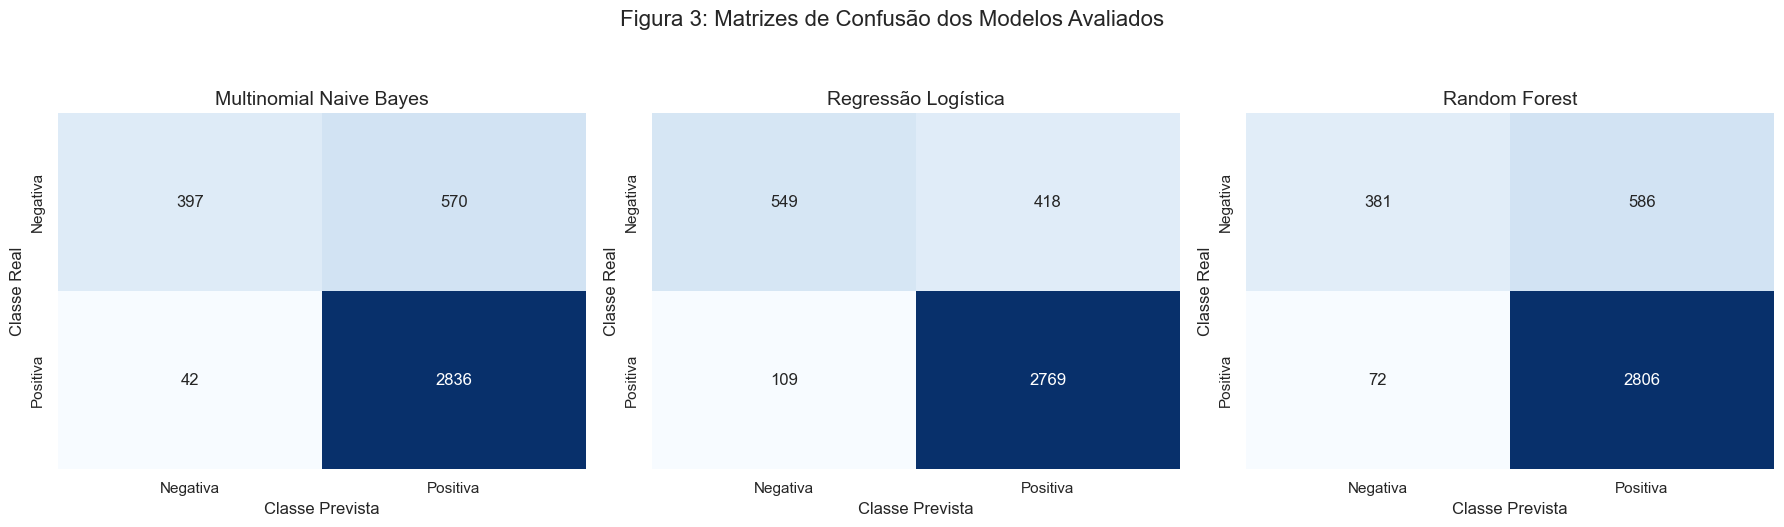

In [10]:
# Figura 3: Matrizes de Confusão dos Modelos Avaliados
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Figura 3: Matrizes de Confusão dos Modelos Avaliados", fontsize=16, y=1.05)

for i, (nome, matriz) in enumerate(matrizes.items()):
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", ax=axes[i], cbar=False)
    axes[i].set_title(nome, fontsize=14)
    axes[i].set_xlabel("Classe Prevista", fontsize=12)
    axes[i].set_ylabel("Classe Real", fontsize=12)
    axes[i].set_xticklabels(["Negativa", "Positiva"])
    axes[i].set_yticklabels(["Negativa", "Positiva"])

plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "figura3_matrizes_confusao.png", dpi=300, bbox_inches="tight")
plt.show()

## 11. Avaliação por classe

Como a base possui uma distribuição diferente entre avaliações positivas e negativas, as métricas também serão analisadas separadamente para cada classe.

Essa análise permite verificar o desempenho dos modelos tanto na identificação das recomendações positivas quanto das recomendações negativas.

In [11]:
for nome, previsoes in modelos.items():
    print(f"\n{'=' * 60}")
    print(nome)
    print(f"{'=' * 60}")
    
    print(
        classification_report(
            y_teste,
            previsoes,
            target_names=["Negativa", "Positiva"],
            digits=4
        )
    )


Multinomial Naive Bayes
              precision    recall  f1-score   support

    Negativa     0.9043    0.4105    0.5647       967
    Positiva     0.8326    0.9854    0.9026      2878

    accuracy                         0.8408      3845
   macro avg     0.8685    0.6980    0.7337      3845
weighted avg     0.8507    0.8408    0.8176      3845


Regressão Logística
              precision    recall  f1-score   support

    Negativa     0.8343    0.5677    0.6757       967
    Positiva     0.8688    0.9621    0.9131      2878

    accuracy                         0.8629      3845
   macro avg     0.8516    0.7649    0.7944      3845
weighted avg     0.8602    0.8629    0.8534      3845


Random Forest
              precision    recall  f1-score   support

    Negativa     0.8411    0.3940    0.5366       967
    Positiva     0.8272    0.9750    0.8951      2878

    accuracy                         0.8289      3845
   macro avg     0.8342    0.6845    0.7158      3845
weighted avg 

## 12. Resumo dos resultados

A tabela abaixo reúne as principais métricas obtidas pelos modelos no conjunto de teste. Os resultados serão utilizados para comparar o desempenho dos classificadores e analisar o comportamento das previsões.

In [12]:
resultados = []

for nome, previsoes in modelos.items():
    resultados.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_teste, previsoes),
        "Precisão": precision_score(y_teste, previsoes),
        "Recall": recall_score(y_teste, previsoes),
        "F1-Score": f1_score(y_teste, previsoes)
    })

df_resultados = pd.DataFrame(resultados)

df_resultados.style.format({
    "Acurácia": "{:.2%}",
    "Precisão": "{:.2%}",
    "Recall": "{:.2%}",
    "F1-Score": "{:.2%}"
})

,Modelo,Acurácia,Precisão,Recall,F1-Score
0,Multinomial Naive Bayes,84.08%,83.26%,98.54%,90.26%
1,Regressão Logística,86.29%,86.88%,96.21%,91.31%
2,Random Forest,82.89%,82.72%,97.50%,89.51%


### Figura 4: Comparação de desempenho dos modelos

O gráfico compara acurácia, precisão, recall e F1-Score dos três modelos. As métricas de precisão, recall e F1-Score são da **classe positiva**. Os valores são lidos diretamente da tabela `df_resultados`, para que a figura sempre corresponda aos resultados do notebook.

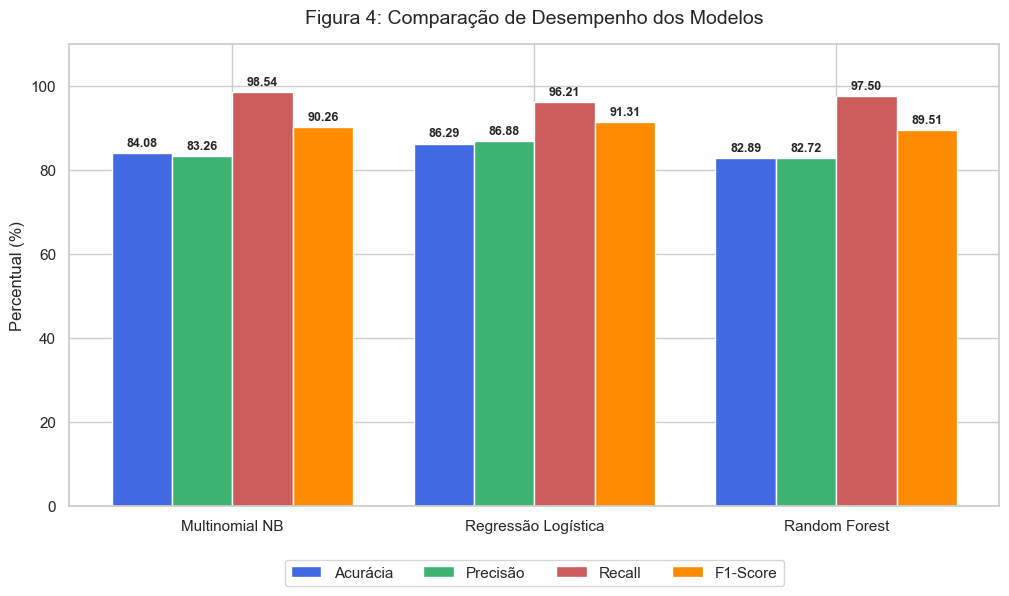

In [13]:
# Figura 4: Comparação de Desempenho dos Modelos (valores lidos da tabela de resultados)
nomes_modelos = ["Multinomial NB", "Regressão Logística", "Random Forest"]
valores = df_resultados[["Acurácia", "Precisão", "Recall", "F1-Score"]] * 100

acuracia = valores["Acurácia"].tolist()
precisao = valores["Precisão"].tolist()
recall = valores["Recall"].tolist()
f1_valores = valores["F1-Score"].tolist()   # nome diferente para não sobrescrever f1_score do sklearn

x = np.arange(len(nomes_modelos))
width = 0.20

fig, ax = plt.subplots(figsize=(12, 6))

rects1 = ax.bar(x - 1.5*width, acuracia, width, label="Acurácia", color="royalblue")
rects2 = ax.bar(x - 0.5*width, precisao, width, label="Precisão", color="mediumseagreen")
rects3 = ax.bar(x + 0.5*width, recall, width, label="Recall", color="indianred")
rects4 = ax.bar(x + 1.5*width, f1_valores, width, label="F1-Score", color="darkorange")

ax.set_ylabel("Percentual (%)", fontsize=12)
ax.set_title("Figura 4: Comparação de Desempenho dos Modelos", fontsize=14, pad=15)
ax.set_xticks(x)
ax.set_xticklabels(nomes_modelos, fontsize=11)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, fontsize=11)

for rects in (rects1, rects2, rects3, rects4):
    ax.bar_label(rects, padding=3, fmt="%.2f", fontsize=9, fontweight="bold")

plt.ylim(0, 110)
plt.savefig(PASTA_FIGURAS / "figura4_comparacao_completa.png", dpi=300, bbox_inches="tight")
plt.show()

## 13. Avaliação das recomendações negativas

Como as avaliações negativas representam uma parcela menor da base, será analisado separadamente o desempenho dos modelos nessa classe.

Essa análise permite verificar a capacidade dos modelos de identificar corretamente avaliações negativas, além das métricas gerais apresentadas anteriormente.

In [14]:
resultados_negativas = []

for nome, previsoes in modelos.items():
    relatorio = classification_report(
        y_teste,
        previsoes,
        output_dict=True
    )

    resultados_negativas.append({
        "Modelo": nome,
        "Precisão - Negativa": relatorio["0"]["precision"],
        "Recall - Negativa": relatorio["0"]["recall"],
        "F1-Score - Negativa": relatorio["0"]["f1-score"]
    })

df_negativas = pd.DataFrame(resultados_negativas)

df_negativas.style.format({
    "Precisão - Negativa": "{:.2%}",
    "Recall - Negativa": "{:.2%}",
    "F1-Score - Negativa": "{:.2%}"
})

,Modelo,Precisão - Negativa,Recall - Negativa,F1-Score - Negativa
0,Multinomial Naive Bayes,90.43%,41.05%,56.47%
1,Regressão Logística,83.43%,56.77%,67.57%
2,Random Forest,84.11%,39.40%,53.66%


## 14. Considerações sobre a modelagem inicial

Os três modelos atingiram acurácia superior a 80% no conjunto de teste: 84,08% (Multinomial Naive Bayes), 86,29% (Regressão Logística) e 82,89% (Random Forest).

A análise por classe mostrou, porém, que os modelos identificam bem as avaliações positivas e **têm dificuldade com as negativas**: o recall da classe negativa ficou entre 39% e 57%. O relatório atribui isso ao desbalanceamento da base (74,86% positivas e 25,14% negativas), o que será **verificado experimentalmente** nas seções seguintes.

Como o objetivo do projeto é identificar pontos de insatisfação, as próximas seções comparam os modelos com um modelo de referência e testam ajustes voltados à classe negativa.